# Linear regression baseline

**IDX Exchange | Week 4**

Estimate `ClosePrice` for California single-family residences using physical property attributes and location. The model should also work for properties that are not listed, so listing and transaction-outcome fields are not predictors.

**Evaluation plan:** train on past sales, use February 2026 for validation, and reserve March 2026 for final testing. The notebook compares ordinary least squares with a log-log variant, then checks whether results hold across earlier monthly cutoffs. The required Week 4 deliverable is the ordinary linear regression baseline and its R²; additional metrics help interpret its errors.

Raw CRMLS files are read without modification. Model selection and training-window decisions must be made before the March test is run.

## 1. Setup

In [21]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

DATA_DIR = Path("../data/raw")
RESULTS_DIR = Path("../results")
TARGET = "ClosePrice"
SKEWED = ["LivingArea", "LotSizeSquareFeet"]       # log-transformed in the log-price model
COUNTS = ["BedroomsTotal", "BathroomsTotalInteger"]
NUMERIC = SKEWED + COUNTS
CATEGORICAL = ["City", "PostalCode"]
FEATURES = NUMERIC + CATEGORICAL
LOW_Q, HIGH_Q = 0.005, 0.995
VAL_MONTH = "202602"
TEST_MONTH = "202603"
# The Week 4 baseline specification is fixed in advance (OLS, all prior months),
# so it is scored on March once. Later model selection uses February only.
RUN_FINAL_TEST = True

# Same fixed validity cap as 02_preprocessing: prices above $100M on ordinary
# homes are data-entry errors (e.g. a $750K listing recorded as a $664M close).
MAX_PRICE = 100_000_000

# Domain plausibility bounds for a single-family home (fixed rules, not learned
# from data). Values outside these ranges are treated as missing, not dropped.
PLAUSIBLE = {"LivingArea": (300, 30_000),
             "BedroomsTotal": (1, 20),
             "BathroomsTotalInteger": (1, 20)}

# Exclude listing-dependent and post-sale fields from model inputs.
EXCLUDED = {"ListPrice", "OriginalListPrice", "DaysOnMarket",
            "CumulativeDaysOnMarket", "PurchaseContractDate",
            "ListingContractDate", "CloseDate", "ClosePrice"}
assert not EXCLUDED.intersection(FEATURES)

print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__)

pandas 3.0.6 | numpy 2.5.3 | sklearn 1.9.1


## 2. Load the raw files

Record a fingerprint of each source file so results can be tied to a specific data pull.

In [22]:
files = sorted(DATA_DIR.glob("CRMLSSold*.csv"))
if not files:
    raise FileNotFoundError(f"No CRMLSSold files in {DATA_DIR.resolve()}")

frames = []
for f in files:
    part = pd.read_csv(f, low_memory=False, dtype={"PostalCode": "string"})
    part["SourceFile"] = f.name
    frames.append(part)
raw = pd.concat(frames, ignore_index=True)
print(f"{len(files)} files, {len(raw):,} rows  ({files[0].name} ... {files[-1].name})")

# Data snapshot: file name, row count, and short SHA-256 hash.
snapshot = pd.DataFrame([
    {"file": f.name, "rows": int((raw["SourceFile"] == f.name).sum()),
     "sha256": hashlib.sha256(f.read_bytes()).hexdigest()[:12]}
    for f in files
])
print("Snapshot fingerprint:",
      hashlib.sha256("".join(snapshot["sha256"]).encode()).hexdigest()[:12])
display(snapshot.tail(3))

27 files, 591,446 rows  (CRMLSSold202401_filled.csv ... CRMLSSold202603.csv)
Snapshot fingerprint: 2ff3877a04bd


,file,rows,sha256
24,CRMLSSold202601.csv,16487,7cb4d45b59cd
25,CRMLSSold202602.csv,19010,0f737b261c72
26,CRMLSSold202603.csv,23372,89add885c9f6


## 3. Clean the transaction records

Apply fixed validity rules before splitting. For repeated listings, remove exact duplicate rows but do not assume that the same `ListingKey` always identifies the same closed transaction. Record the number of rows removed at each step.

Physical attributes that are zero, negative, or outside the `PLAUSIBLE` bounds are set to missing rather than dropping the sale; these counts are logged separately.

In [23]:
steps = []

def log_step(name, before, after):
    steps.append({"step": name, "removed": before - after, "rows_left": after})

def clean_text(series, width=None):
    s = series.astype("string").str.strip().str.upper()
    if width is not None:
        s = s.str[:width]
    s = s.mask(s.eq(""))
    # NumPy NaN rather than pandas NA is compatible with sklearn imputers.
    return pd.Series(s.astype(object).where(s.notna(), np.nan), index=series.index)

df = raw.copy()
previous = len(df)

df = df.loc[(df["PropertyType"] == "Residential") &
            (df["PropertySubType"] == "SingleFamilyResidence")].copy()
log_step("Single-family residences", previous, len(df))
previous = len(df)

# Ignore SourceFile so the same record exported in two monthly files is caught.
df = df.drop_duplicates(subset=[c for c in df.columns if c != "SourceFile"]).copy()
log_step("Exact duplicates", previous, len(df))
previous = len(df)

# A repeated ListingKey may be an update or a different transaction.
if "ListingKey" in df.columns:
    repeated_keys = df["ListingKey"].duplicated(keep=False).sum()
    transaction_fields = ["ListingKey", "CloseDate", "ClosePrice"]
    print("Rows with repeated ListingKey:", repeated_keys)
    print("Repeated listing/date/price combinations:",
          df.duplicated(subset=transaction_fields).sum())

df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")
df = df.loc[df["CloseDate"].notna()].copy()
log_step("Missing CloseDate", previous, len(df))
previous = len(df)

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.loc[df[TARGET] > 0].copy()
log_step("Missing or non-positive ClosePrice", previous, len(df))
previous = len(df)

df = df.loc[df[TARGET] <= MAX_PRICE].copy()
log_step("ClosePrice above $100M", previous, len(df))
previous = len(df)

if "ListingContractDate" in df.columns:
    listed = pd.to_datetime(df["ListingContractDate"], errors="coerce")
    df = df.loc[~(df["CloseDate"] < listed)].copy()
    log_step("CloseDate before listing date", previous, len(df))
    previous = len(df)

set_missing = {}
for col in NUMERIC:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    # Negative physical quantities are invalid; zero is often unreported.
    invalid = df[col] <= 0
    if col in PLAUSIBLE:
        low, high = PLAUSIBLE[col]
        invalid |= ~df[col].between(low, high) & df[col].notna()
    set_missing[col] = int(invalid.sum())
    df.loc[invalid, col] = np.nan

df["City"] = clean_text(df["City"])
df["PostalCode"] = clean_text(df["PostalCode"], width=5)
df["CloseMonth"] = df["CloseDate"].dt.strftime("%Y%m")

# Some exports contain the same closed transaction with non-identical metadata.
# Investigate these rather than dropping them automatically.
display(pd.DataFrame(steps))
print("Rows after fixed cleaning:", f"{len(df):,}")
print("Invalid physical values set to missing:", set_missing)

Rows with repeated ListingKey: 454
Repeated listing/date/price combinations: 0


,step,removed,rows_left
0,Single-family residences,294201,297245
1,Exact duplicates,29,297216
2,Missing CloseDate,0,297216
3,Missing or non-positive ClosePrice,3,297213
4,ClosePrice above $100M,20,297193
5,CloseDate before listing date,41,297152


Rows after fixed cleaning: 297,152
Invalid physical values set to missing: {'LivingArea': 151, 'LotSizeSquareFeet': 151, 'BedroomsTotal': 177, 'BathroomsTotalInteger': 139}


## 4. Split by closing month

Use `CloseDate` rather than the CSV filename to determine when a transaction closed. March 2026 is the most recent test month specified for this dataset; February is reserved for validation. If later data appears in the raw folder, stop and review the split instead of silently changing it.

In [24]:
src_month = df["SourceFile"].str.extract(r"(\d{6})")[0]
print("Source-month / closing-month mismatch:",
      f"{(src_month != df['CloseMonth']).mean():.2%}")
months = sorted(df["CloseMonth"].unique())
assert VAL_MONTH in months and TEST_MONTH in months, "Expected months missing"
assert months[-1] == TEST_MONTH, ("Latest closing month is", months[-1],
                                  "— review the evaluation dates")
print("Training months:", months[0], "through", months[months.index(VAL_MONTH)-1])
print("Validation:", VAL_MONTH, "| Final test:", TEST_MONTH)
print("Closing counts in recent months:")
print(df.groupby("CloseMonth").size().tail(6).to_string())
print("March test rows reserved:", (df["CloseMonth"] == TEST_MONTH).sum())

Source-month / closing-month mismatch: 0.00%
Training months: 202401 through 202601
Validation: 202602 | Final test: 202603
Closing counts in recent months:
CloseMonth
202510    12027
202511     9735
202512    10453
202601     7489
202602     8958
202603    11560
March test rows reserved: 11560


## 5. Baseline and evaluation functions

The primary Week 4 model is ordinary least squares on the original price scale, with median imputation (plus missing-value indicators) and scaling for numeric fields, and one-hot encoding for city and ZIP.

A second linear regression is fitted to log-price as a comparison because prices are right-skewed. It also log-transforms living area and lot size (a log-log specification). Without that, the exponentiated prediction grows exponentially with square footage, and a few very large homes receive predictions an order of magnitude too high (for example, an $8M, 17,000 sq ft sale predicted near $89M), which destroys R² even when MdAPE looks good.

All preprocessing is fitted inside the model pipeline on the training portion of each split. Price outlier thresholds (0.5th and 99.5th percentiles) are also computed from that training portion only, following the IDX AVM best-practices document. We report both filtered and full-month metrics because filtering changes the evaluation population.

City and ZIP are one-hot encoded, with categories seen fewer than 20 times grouped together. That is adequate for a linear baseline; target encoding fitted within folds is a candidate for the tree models in later weeks.

In [25]:
def model_inputs(frame):
    """Keep numeric columns numeric and normalize categorical missing values."""
    x = frame[FEATURES].copy()
    for col in NUMERIC:
        x[col] = pd.to_numeric(x[col], errors="coerce").astype("float64")
    for col in CATEGORICAL:
        x[col] = clean_text(x[col])
    return x


def numeric_pipeline(log_features=False):
    steps = []
    if log_features:
        # log1p keeps NaN as NaN, so imputation still sees the missing values.
        steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    steps += [
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]
    return Pipeline(steps)


def make_model(log_target=False):
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
        ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
    ])
    prep = ColumnTransformer([
        ("size", numeric_pipeline(log_features=log_target), SKEWED),
        ("counts", numeric_pipeline(), COUNTS),
        ("categorical", categorical, CATEGORICAL),
    ])
    pipeline = Pipeline([("preprocess", prep), ("regression", LinearRegression())])
    if log_target:
        return TransformedTargetRegressor(
            regressor=pipeline, func=np.log, inverse_func=np.exp,
            check_inverse=False,
        )
    return pipeline


MODELS = {"Linear regression": False, "Log-log linear regression": True}


def score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if len(y_true) == 0:
        raise ValueError("No observations in evaluation subset")
    error = (y_pred - y_true) / y_true
    absolute_pct_error = np.abs(error)
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE_USD": mean_absolute_error(y_true, y_pred),
        "MAPE_pct": 100 * absolute_pct_error.mean(),
        "MdAPE_pct": 100 * np.median(absolute_pct_error),
        "PPE10_pct": 100 * (absolute_pct_error <= 0.10).mean(),
        "PPE20_pct": 100 * (absolute_pct_error <= 0.20).mean(),
        "median_bias_pct": 100 * np.median(error),
        "negative_predictions": int((y_pred < 0).sum()),
        "N": len(y_true),
    }


def metrics_table(results, scope="filtered"):
    return pd.DataFrame({name: res[scope] for name, res in results.items()}).T.round(3)


def run_cutoff(eval_month, n_train_months=None, model_names=None):
    prior_months = [month for month in months if month < eval_month]
    if n_train_months is not None:
        prior_months = prior_months[-n_train_months:]
    train = df.loc[df["CloseMonth"].isin(prior_months)]
    evaluate = df.loc[df["CloseMonth"] == eval_month]
    if train.empty or evaluate.empty:
        raise ValueError(f"Insufficient observations for {eval_month}")

    lower, upper = train[TARGET].quantile([LOW_Q, HIGH_Q])
    train_fit = train.loc[train[TARGET].between(lower, upper)]
    in_range = evaluate[TARGET].between(lower, upper)
    x_train = model_inputs(train_fit)
    x_eval = model_inputs(evaluate)

    results = {}
    for name, use_log in MODELS.items():
        if model_names is not None and name not in model_names:
            continue
        fitted = make_model(use_log).fit(x_train, train_fit[TARGET])
        pred = pd.Series(fitted.predict(x_eval), index=evaluate.index)
        results[name] = {
            "pred": pred,
            "filtered": score(evaluate.loc[in_range, TARGET], pred.loc[in_range]),
            "all": score(evaluate[TARGET], pred),
        }
    return {"month": eval_month, "n_train": len(train_fit),
            "lower": lower, "upper": upper, "coverage": in_range.mean(),
            "evaluate": evaluate, "in_range": in_range, "results": results}

## 6. February validation and historical checks

Start with the required linear regression baseline. Compare the log-price variant on the same February validation data. Three earlier cutoffs provide a basic check on whether the result is specific to one month. March is not scored here.

In [26]:
cutoffs = months[-5:-1]  # three earlier months plus February 2026
assert cutoffs[-1] == VAL_MONTH and TEST_MONTH not in cutoffs
runs = {month: run_cutoff(month) for month in cutoffs}
val = runs[VAL_MONTH]

print("February validation training observations:", f"{val['n_train']:,}")
print("Training-derived price bounds:",
      f"${val['lower']:,.0f} – ${val['upper']:,.0f}")
print("Validation coverage:", f"{val['coverage']:.2%}")
print("Metrics within the training-derived price bounds:")
display(metrics_table(val["results"]))
print("Metrics for all valid February sales:")
display(metrics_table(val["results"], scope="all"))

February validation training observations: 273,904
Training-derived price bounds: $190,000 – $8,287,751
Validation coverage: 99.01%
Metrics within the training-derived price bounds:


,R2,MAE_USD,MAPE_pct,MdAPE_pct,PPE10_pct,PPE20_pct,median_bias_pct,negative_predictions,N
Linear regression,0.811,247364.606,23.323,16.804,31.086,57.492,-0.791,19.0,8869.0
Log-log linear regression,0.832,193244.020,14.727,10.594,47.784,76.942,-0.538,0.0,8869.0


Metrics for all valid February sales:


,R2,MAE_USD,MAPE_pct,MdAPE_pct,PPE10_pct,PPE20_pct,median_bias_pct,negative_predictions,N
Linear regression,0.655,282249.425,25.158,16.974,30.81,56.988,-0.924,30.0,8958.0
Log-log linear regression,0.711,225303.494,16.459,10.736,47.31,76.178,-0.516,0.0,8958.0


,month,model,R2,MdAPE_pct,coverage
0,202511,Linear regression,0.811,16.472,0.988
1,202511,Log-log linear regression,0.836,10.045,0.988
2,202512,Linear regression,0.799,16.772,0.988
3,202512,Log-log linear regression,0.830,10.079,0.988
4,202601,Linear regression,0.801,17.121,0.987
5,202601,Log-log linear regression,0.821,10.603,0.987
6,202602,Linear regression,0.811,16.804,0.990
7,202602,Log-log linear regression,0.832,10.594,0.990


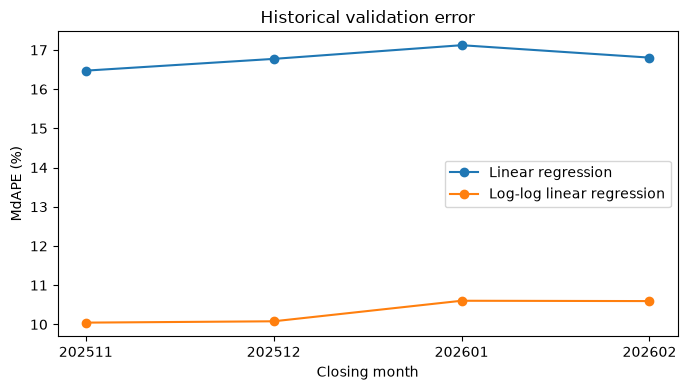

In [27]:
backtest = pd.DataFrame([
    {"month": month, "model": name,
     "R2": res["filtered"]["R2"],
     "MdAPE_pct": res["filtered"]["MdAPE_pct"],
     "coverage": runs[month]["coverage"]}
    for month in cutoffs
    for name, res in runs[month]["results"].items()
])
display(backtest.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for name, group in backtest.groupby("model"):
    ax.plot(group["month"], group["MdAPE_pct"], marker="o", label=name)
ax.set(xlabel="Closing month", ylabel="MdAPE (%)", title="Historical validation error")
ax.legend()
plt.tight_layout()
plt.show()

### Training-window sensitivity

The internship plan asks us to treat training-window length as a modeling choice. Compare candidate windows using **earlier historical cutoffs**, not March. This is exploratory: don't choose a window based on the final test score.

In [28]:
window_results = []
for window in [3, 6, 12, 18, None]:
    for month in cutoffs[:-1]:  # historical cutoffs, excluding February
        result = run_cutoff(month, n_train_months=window,
                            model_names=["Linear regression"])
        m = result["results"]["Linear regression"]["filtered"]
        window_results.append({"months": str(window) if window else "all",
                               "eval_month": month, "R2": m["R2"],
                               "MdAPE_pct": m["MdAPE_pct"]})
window_table = pd.DataFrame(window_results)
display(window_table.groupby("months").agg(
    mean_R2=("R2", "mean"), mean_MdAPE_pct=("MdAPE_pct", "mean")
).sort_values("mean_MdAPE_pct").round(3))

# Keep the full-history fit as the Week 4 baseline unless a change is
# justified and documented using the historical checks above.

,mean_R2,mean_MdAPE_pct
months,,
all,0.804,16.788
18,0.803,16.846
12,0.798,17.273
6,0.789,17.485
3,0.752,18.463


## 7. Error analysis

Inspect the **ordinary linear regression baseline** by price band and city. The log-target comparison is useful, but it should not silently replace the required Week 4 baseline. Only report city groups with enough February transactions to interpret.

By price band:


,n,MdAPE_pct,median_bias_pct
price_band,,,
"(189999.999, 559000.0]",1775,29.60,-9.62
"(559000.0, 770000.0]",1777,18.88,0.15
"(770000.0, 1040000.0]",1783,14.75,4.16
"(1040000.0, 1585000.0]",1769,12.45,3.30
"(1585000.0, 8240000.0]",1765,14.18,-5.72


15 highest-volume cities with at least 30 sales:


,n,MdAPE_pct
City,,
LOS ANGELES,378,19.37
SAN DIEGO,368,10.29
RIVERSIDE,142,25.19
SAN JOSE,129,13.83
MENIFEE,106,26.79
OAKLAND,105,20.93
OCEANSIDE,98,16.72
MURRIETA,97,22.22
LANCASTER,94,31.07


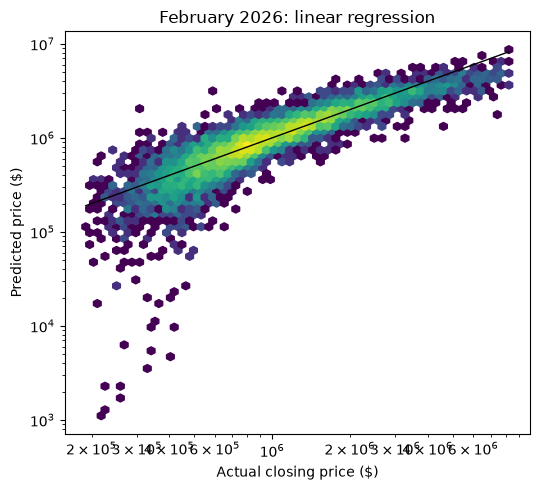

Non-positive predictions omitted from log plot: 19


In [29]:
baseline = "Linear regression"
eval_data = val["evaluate"].loc[val["in_range"], ["City", TARGET]].copy()
eval_data["prediction"] = val["results"][baseline]["pred"].loc[eval_data.index]
eval_data["signed_pct"] = 100 * (eval_data["prediction"] - eval_data[TARGET]) / eval_data[TARGET]
eval_data["APE_pct"] = eval_data["signed_pct"].abs()
eval_data["price_band"] = pd.qcut(eval_data[TARGET], 5, duplicates="drop")

by_band = eval_data.groupby("price_band", observed=True).agg(
    n=("APE_pct", "size"), MdAPE_pct=("APE_pct", "median"),
    median_bias_pct=("signed_pct", "median"),
)
by_city = (eval_data.groupby("City", dropna=False)["APE_pct"]
           .agg(n="size", MdAPE_pct="median")
           .query("n >= 30").sort_values("n", ascending=False).head(15))
print("By price band:")
display(by_band.round(2))
print("15 highest-volume cities with at least 30 sales:")
display(by_city.round(2))

positive = eval_data["prediction"] > 0
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.hexbin(eval_data.loc[positive, TARGET],
          eval_data.loc[positive, "prediction"],
          gridsize=55, xscale="log", yscale="log", bins="log", mincnt=1)
limits = [eval_data[TARGET].min(), eval_data[TARGET].max()]
ax.plot(limits, limits, color="black", linewidth=1)
ax.set(xlabel="Actual closing price ($)", ylabel="Predicted price ($)",
       title="February 2026: linear regression")
plt.tight_layout()
plt.show()
print("Non-positive predictions omitted from log plot:", (~positive).sum())

## 8. Final test

March 2026 is the held-out test month. The Week 4 plan asks for the baseline's test R², and both linear specifications were fixed before March was scored: all prior months for training (supported by the window check above) and no tuning. Each model is refit on all eligible sales before March, including February.

Later weeks must select and tune models on February and the historical cutoffs, not on these March numbers. Both filtered and full-market metrics are reported, along with the share of sales covered by the price bounds.

In [30]:
# Set these based on historical validation, *before* enabling final testing.
FINAL_MODELS = list(MODELS)
FINAL_TRAIN_MONTHS = None  # None = all available months before March

if RUN_FINAL_TEST:
    final = run_cutoff(TEST_MONTH, n_train_months=FINAL_TRAIN_MONTHS,
                       model_names=FINAL_MODELS)
    print("March 2026 test coverage:", f"{final['coverage']:.2%}")
    print("Filtered test metrics:")
    display(metrics_table(final["results"]))
    print("All valid March sales:")
    display(metrics_table(final["results"], scope="all"))
else:
    print("March 2026 held out; no test results computed.")

March 2026 test coverage: 98.79%
Filtered test metrics:


,R2,MAE_USD,MAPE_pct,MdAPE_pct,PPE10_pct,PPE20_pct,median_bias_pct,negative_predictions,N
Linear regression,0.812,238462.424,22.551,16.600,32.688,57.767,-1.355,22.0,11420.0
Log-log linear regression,0.826,186273.367,14.113,10.035,49.860,78.722,-1.283,0.0,11420.0


All valid March sales:


,R2,MAE_USD,MAPE_pct,MdAPE_pct,PPE10_pct,PPE20_pct,median_bias_pct,negative_predictions,N
Linear regression,0.632,288653.943,23.681,16.857,32.344,57.145,-1.524,32.0,11560.0
Log-log linear regression,0.698,230357.875,15.277,10.195,49.265,77.820,-1.287,0.0,11560.0


### Save metrics

Write every scored split to one file so the Week 5 models can be compared against the same numbers.

In [31]:
records = []
scored = dict(runs)
if RUN_FINAL_TEST:
    scored[TEST_MONTH] = final
for month, run in scored.items():
    split = ("test" if month == TEST_MONTH
             else "validation" if month == VAL_MONTH else "backtest")
    for name, res in run["results"].items():
        for scope in ("filtered", "all"):
            records.append({"split": split, "month": month, "model": name,
                            "scope": scope, "coverage": run["coverage"],
                            **res[scope]})
baseline_metrics = pd.DataFrame(records)

RESULTS_DIR.mkdir(exist_ok=True)
baseline_metrics.to_csv(RESULTS_DIR / "baseline_metrics.csv", index=False)
snapshot.to_csv(RESULTS_DIR / "data_snapshot.csv", index=False)
print("Saved", len(baseline_metrics), "rows to", RESULTS_DIR / "baseline_metrics.csv")

Saved 20 rows to ../results/baseline_metrics.csv


## 9. Results and notes

Numbers below are copied from the executed outputs above (data snapshot `2ff3877a04bd`, 297,152 sales after cleaning). "Filtered" means sales within the training-derived 0.5th–99.5th percentile price bounds; "all" includes every valid sale in the month.

**February 2026 validation** (filtered, N = 8,869, coverage 99.0%)

| Model | R² | MAE ($) | MAPE (%) | MdAPE (%) | Within 10% | Within 20% |
|---|---:|---:|---:|---:|---:|---:|
| Linear regression (baseline) | 0.811 | 247,365 | 23.3 | 16.8 | 31.1% | 57.5% |
| Log-log linear regression | 0.832 | 193,244 | 14.7 | 10.6 | 47.8% | 76.9% |

**March 2026 test** (models fixed beforehand; refit on all months through February)

| Model | Scope | R² | MAE ($) | MAPE (%) | MdAPE (%) | N |
|---|---|---:|---:|---:|---:|---:|
| Linear regression (baseline) | filtered | **0.812** | 238,462 | 22.6 | 16.6 | 11,420 |
| Linear regression (baseline) | all | 0.632 | 288,654 | 23.7 | 16.9 | 11,560 |
| Log-log linear regression | filtered | 0.826 | 186,273 | 14.1 | 10.0 | 11,420 |
| Log-log linear regression | all | 0.698 | 230,358 | 15.3 | 10.2 | 11,560 |

**Findings**

- **Historical stability:** Across the four cutoffs (November 2025 – February 2026), baseline R² stayed between 0.799 and 0.811 and MdAPE between 16.5% and 17.1%. March (16.6%) is in the same range, so the result is not specific to one month.
- **Training window:** Using all available months was best on the historical cutoffs (mean MdAPE 16.8%, vs. 16.8% for 18 months, 17.3% for 12, 17.5% for 6, and 18.5% for 3). All months were retained.
- **Error patterns:** Error is largest for the cheapest homes. The bottom price quintile (under $559K) has 29.6% MdAPE and is under-predicted (median bias −9.6%). Homes above $770K have 12–15% MdAPE; the middle bands are slightly over-predicted (+3–4%) and the top band under-predicted (−5.7%), the pattern expected when a linear fit flattens the extremes. Inland Empire and high-desert cities (Hemet 36.6%, Lancaster 31.1%, Menifee 26.8%) have much larger errors than San Diego (10.3%) or Long Beach (14.4%).
- **Log-log comparison:** Modeling log-price against log living area and log lot size cuts MdAPE by about 6.5 points and removes negative predictions (the baseline predicts a negative price for about 20 sales per month). It is the stronger linear reference for Week 5.
- **Filtered vs. all:** R² drops from 0.81 to 0.63 when the ~1.2% of sales outside the price bounds are included, while MdAPE barely changes. A small number of luxury sales dominate squared-error metrics, which is why MdAPE is the headline metric.

**Assumptions and limitations**

- Training and evaluation include only sold properties. Performance on unsold/off-market properties cannot be directly verified with this dataset.
- Location is represented by city and ZIP code, not school boundaries or fine-grained geographic features.
- Missing physical characteristics are median-imputed with missing-value indicators. Values outside fixed plausibility bounds (living area 300–30,000 sq ft, 1–20 bedrooms or bathrooms) are treated as missing.
- Sales above $100M are treated as data-entry errors and removed (20 rows), matching `02_preprocessing`.
- `ListingContractDate` is used only to drop logically impossible records (close before listing), never as a model input.
- The 0.5th–99.5th percentile price filter is learned from each training period. Metrics for filtered sales do not represent the entire market; full-month metrics and coverage are shown alongside them.
- The model does not yet account for nonlinear interactions, property condition, renovation history, or neighborhood comparable sales.

**Reproducibility:** Linear regression has no random component. Package versions are pinned in `requirements.txt`; source-file hashes are saved to `results/data_snapshot.csv` and all metrics to `results/baseline_metrics.csv`.

**Next step:** Compare Decision Tree and Random Forest models against both linear baselines in Week 5, using February and the same historical cutoffs for model selection. March stays untouched until those choices are final.

**References:** IDX Exchange, *Data Science v.4* (Week 4); *AVM Data Science Best Practices* (chronological splits, outlier thresholds, leakage, MdAPE); Data School tutorials on scikit-learn pipelines; StatQuest, *Linear Regression, Clearly Explained*.